In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RAIZ = Path("..")
RESULTADOS = RAIZ / "resultados"
FIGURAS = RAIZ / "figuras"
FIGURAS.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
atricion = pd.read_csv(RESULTADOS / "principal" / "attrition.csv")
atricion

,step,description,n_persons,n_excluded
0,0,Todas las personas en la base OMOP,11548,0
1,1,Con al menos 1 diagnóstico(s) de epilepsia,424,11124
2,2,Edad >= 0 años en la fecha índice,424,0
3,3,>= 365 días de observación previa,183,241
4,4,Antiepiléptico dentro de 365 días tras la fech...,103,80


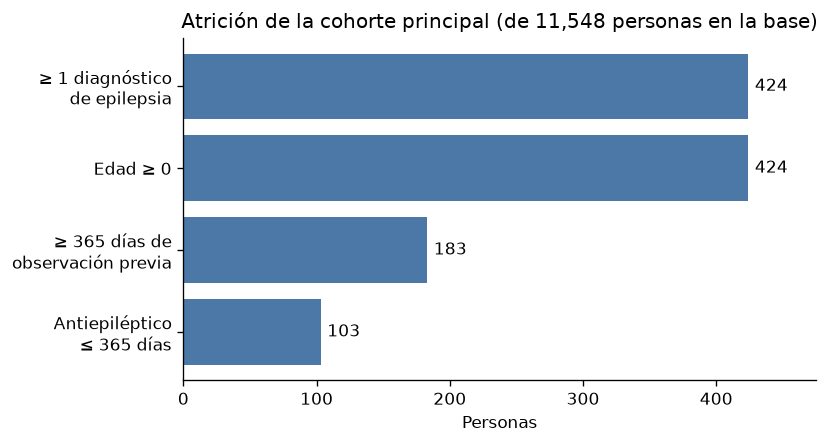

In [3]:
etiquetas = {
    1: "≥ 1 diagnóstico\nde epilepsia",
    2: "Edad ≥ 0",
    3: "≥ 365 días de\nobservación previa",
    4: "Antiepiléptico\n≤ 365 días",
}
embudo = atricion[atricion["step"] >= 1].copy()
embudo["etiqueta"] = embudo["step"].map(etiquetas)

fig, ax = plt.subplots(figsize=(7, 3.8))
barras = ax.barh(embudo["etiqueta"], embudo["n_persons"], color="#4C78A8")
ax.invert_yaxis()
ax.set_xlabel("Personas")
ax.set_title("Atrición de la cohorte principal (de 11,548 personas en la base)")
for barra, n in zip(barras, embudo["n_persons"]):
    ax.text(n + 5, barra.get_y() + barra.get_height() / 2, f"{n}", va="center")
ax.set_xlim(0, embudo["n_persons"].max() * 1.12)
fig.tight_layout()
fig.savefig(FIGURAS / "01_atricion.png", dpi=200)
plt.show()

In [4]:
sexo = pd.read_csv(RESULTADOS / "principal" / "table1_sexo.csv")
edad = pd.read_csv(RESULTADOS / "principal" / "table1_edad.csv")
sexo, edad

(  sex   n   pct
 0   F  48  46.6
 1   M  55  53.4,
   grupo_edad   n   pct
 0       0-17  65  63.1
 1      18-64  32  31.1
 2        65+   6   5.8)

In [5]:
def barras_con_porcentaje(ax, categorias, n, pct, color="#4C78A8"):
    barras = ax.bar(categorias, n, color=color)
    for barra, valor, p in zip(barras, n, pct):
        ax.text(
            barra.get_x() + barra.get_width() / 2,
            valor + max(n) * 0.02,
            f"{valor} ({p:.1f} %)",
            ha="center",
        )
    ax.set_ylim(0, max(n) * 1.15)
    ax.set_ylabel("Personas")

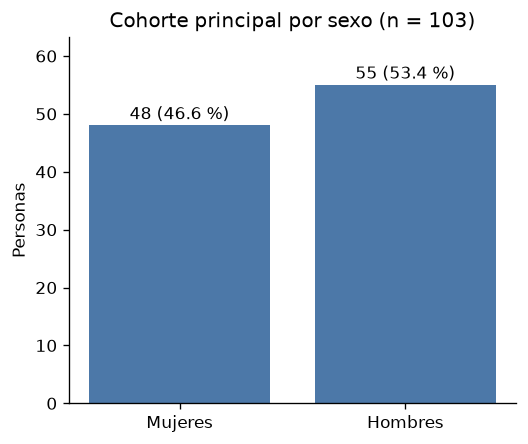

In [6]:
orden_sexo = ["F", "M"]
nombres_sexo = {"F": "Mujeres", "M": "Hombres"}
s = sexo.set_index("sex").loc[orden_sexo]

fig, ax = plt.subplots(figsize=(4.5, 3.8))
barras_con_porcentaje(ax, [nombres_sexo[x] for x in s.index], s["n"], s["pct"])
ax.set_title("Cohorte principal por sexo (n = 103)")
fig.tight_layout()
fig.savefig(FIGURAS / "02_sexo.png", dpi=200)
plt.show()

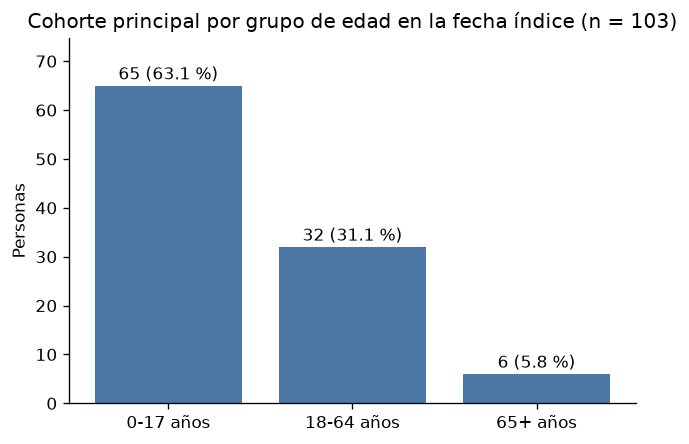

In [7]:
orden_edad = ["0-17", "18-64", "65+"]
e = edad.set_index("grupo_edad").loc[orden_edad]

fig, ax = plt.subplots(figsize=(5.5, 3.8))
barras_con_porcentaje(ax, [f"{g} años" for g in e.index], e["n"], e["pct"])
ax.set_title("Cohorte principal por grupo de edad en la fecha índice (n = 103)")
fig.tight_layout()
fig.savefig(FIGURAS / "03_edad.png", dpi=200)
plt.show()

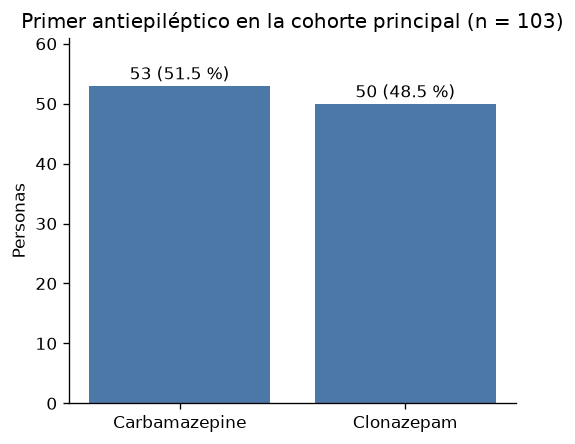

In [8]:
aed = pd.read_csv(RESULTADOS / "principal" / "primer_aed.csv")
aed = aed.sort_values("n", ascending=False)

fig, ax = plt.subplots(figsize=(4.5, 3.8))
barras_con_porcentaje(ax, aed["medicamento"].str.capitalize(), aed["n"], aed["pct"])
ax.set_title("Primer antiepiléptico en la cohorte principal (n = 103)")
fig.tight_layout()
fig.savefig(FIGURAS / "04_primer_aed.png", dpi=200)
plt.show()

In [10]:
variantes = {
    "sin_observacion_previa": "Sin observación previa",
    "observacion_180": "Observación ≥ 180 días",
    "principal": "Principal (365 días)",
    "dos_diagnosticos": "≥ 2 diagnósticos",
    "solo_adultos": "Solo adultos",
}

filas = []
for clave, nombre in variantes.items():
    tabla = pd.read_csv(RESULTADOS / clave / "attrition.csv")
    filas.append({"variante": nombre, "n_final": int(tabla["n_persons"].iloc[-1])})

sensibilidad = pd.DataFrame(filas)
sensibilidad

,variante,n_final
0,Sin observación previa,153
1,Observación ≥ 180 días,123
2,Principal (365 días),103
3,≥ 2 diagnósticos,55
4,Solo adultos,38


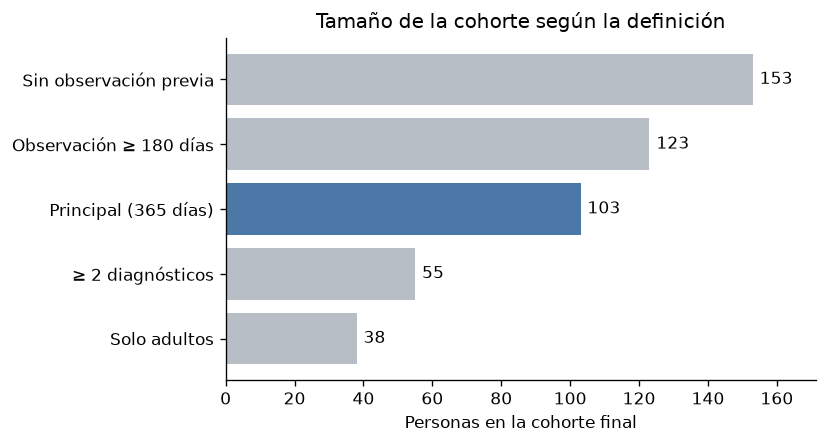

In [11]:
colores = ["#4C78A8" if v.startswith("Principal") else "#B8BEC6" for v in sensibilidad["variante"]]

fig, ax = plt.subplots(figsize=(7, 3.8))
barras = ax.barh(sensibilidad["variante"], sensibilidad["n_final"], color=colores)
ax.invert_yaxis()
ax.set_xlabel("Personas en la cohorte final")
ax.set_title("Tamaño de la cohorte según la definición")
for barra, n in zip(barras, sensibilidad["n_final"]):
    ax.text(n + 2, barra.get_y() + barra.get_height() / 2, f"{n}", va="center")
ax.set_xlim(0, sensibilidad["n_final"].max() * 1.12)
fig.tight_layout()
fig.savefig(FIGURAS / "05_sensibilidad.png", dpi=200)
plt.show()